# Predicting Friction in AI-Generated Pull Requests

**Dataset:** `AIDev-pop` subset from [hao-li/AIDev on Hugging Face](https://huggingface.co/datasets/hao-li/AIDev) ([Research Repo](https://github.com/SAILResearch/AI_Teammates_in_SE3)).

Set `AIDEV_DATA_DIR` or place the extracted `scope/<Agent>/` files under `./data/aidev_pop/scope` before running.


In [5]:
import pandas as pd
import json
import os

# Configure path to the extracted AIDev-pop scope directory
base_dir = os.environ.get("AIDEV_DATA_DIR", "./data/aidev_pop/scope")
agents = ["Claude_Code", "Copilot", "Cursor", "Devin", "OpenAI_Codex"]

all_prs = []

for agent in agents:
    agent_dir = os.path.join(base_dir, agent)
    prs_path = os.path.join(agent_dir, "prs.csv")
    reviews_path = os.path.join(agent_dir, "pr_reviews.json")

    if not os.path.exists(prs_path) or not os.path.exists(reviews_path):
        print(f"Warning: Files not found for agent '{agent}' at {prs_path} or {reviews_path}. Skipping.")
        continue

    # Read the Pull Requests Metadata
    df = pd.read_csv(prs_path)
    df['agent_identity'] = agent  # Add our Agent feature!

    # Load the Reviews JSON to calculate Review Cycles
    with open(reviews_path, 'r', encoding='utf-8') as f:
        reviews_data = json.load(f)

    # Function to count the number of review items (review cycles) for a given PR
    def get_review_cycles(pr_id):
        # The JSON keys are formatted like "3205734508.json"
        key = f"{pr_id}.json"
        if key in reviews_data:
            return len(reviews_data[key])
        return 0

    # Apply function to count review cycles
    df['review_cycles'] = df['id'].apply(get_review_cycles)

    all_prs.append(df)

# Combine all agents into one dataframe
raw_data = pd.concat(all_prs, ignore_index=True)
print(f"Total PRs loaded: {len(raw_data)}")
print(raw_data['agent_identity'].value_counts())

Total PRs loaded: 33600
agent_identity
OpenAI_Codex    21800
Copilot          4971
Devin            4829
Cursor           1541
Claude_Code       459
Name: count, dtype: int64


In [6]:
# 1. DEFINE THE TARGET VARIABLE
# 0 = Smoothly Merged (<= 1 review cycles)
# 1 = Heavy Review (>= 2 review cycles)
raw_data['target_heavy_review'] = raw_data['review_cycles'].apply(lambda x: 1 if x >= 2 else 0)

# 2. FEATURE ENGINEERING
# Feature: PR Description Length (Word Count)
raw_data['pr_desc_length'] = raw_data['body'].fillna('').apply(lambda x: len(str(x).split()))

# Feature: One-Hot Encoding for Agent Identity
# This creates columns like agent_Claude_Code, agent_Copilot, etc., with 0s and 1s.
ml_data = pd.get_dummies(raw_data, columns=['agent_identity'], prefix='agent')

# Keep only the features we need for our ML model
features_to_keep = [
    'id', 'target_heavy_review', 'review_cycles', 'pr_desc_length',
    'agent_Claude_Code', 'agent_Copilot', 'agent_Cursor', 'agent_Devin', 'agent_OpenAI_Codex'
]

# Ensure we only keep columns that exist (in case an agent had no data)
features_to_keep = [col for col in features_to_keep if col in ml_data.columns]
ml_dataset = ml_data[features_to_keep]

print("Target Variable Distribution:")
print(ml_dataset['target_heavy_review'].value_counts())
print("\nFirst 5 rows of our ML Dataset:")
display(ml_dataset.head())


Target Variable Distribution:
target_heavy_review
0    29027
1     4573
Name: count, dtype: int64

First 5 rows of our ML Dataset:


,id,target_heavy_review,review_cycles,pr_desc_length,agent_Claude_Code,agent_Copilot,agent_Cursor,agent_Devin,agent_OpenAI_Codex
0,3264933329,0,0,256,True,False,False,False,False
1,3265118634,0,0,49,True,False,False,False,False
2,3265640341,1,2,554,True,False,False,False,False
3,3265709660,0,1,312,True,False,False,False,False
4,3265782173,0,0,37,True,False,False,False,False


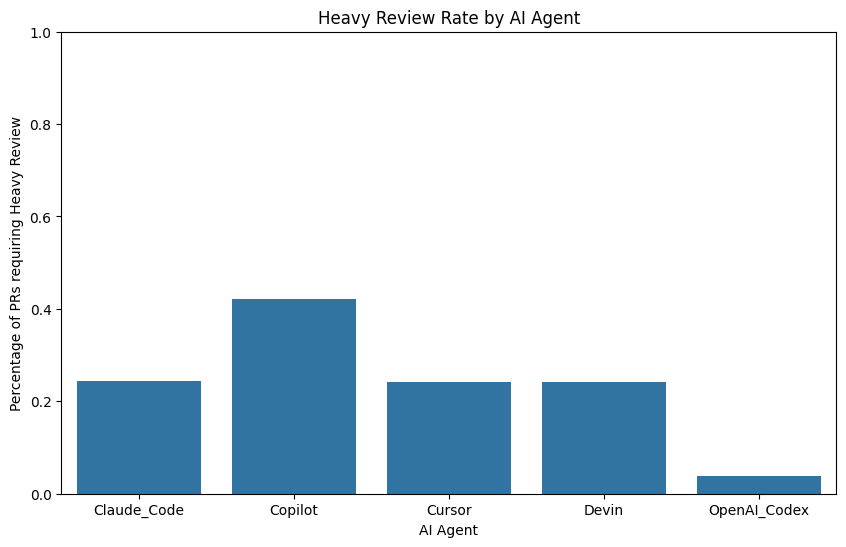

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate "Heavy Review" rate by Agent
agent_performance = raw_data.groupby('agent_identity')['target_heavy_review'].mean().reset_index()
agent_performance.rename(columns={'target_heavy_review': 'Heavy Review Rate'}, inplace=True)

# Plot the results
plt.figure(figsize=(10, 6))
sns.barplot(x='agent_identity', y='Heavy Review Rate', data=agent_performance)
plt.title('Heavy Review Rate by AI Agent')
plt.ylabel('Percentage of PRs requiring Heavy Review')
plt.xlabel('AI Agent')
plt.ylim(0, 1) # Set Y axis from 0 to 100%
plt.show()


In [8]:
import numpy as np

# ---------------------------------------------------------
# 1. TIMELINE FEATURES (Time to Merge)
# ---------------------------------------------------------
# Convert strings to datetime
raw_data['created_at'] = pd.to_datetime(raw_data['created_at'])
raw_data['merged_at'] = pd.to_datetime(raw_data['merged_at'], errors='coerce')

# Calculate hours to merge (ignoring PRs that were never merged)
raw_data['hours_to_merge'] = (raw_data['merged_at'] - raw_data['created_at']).dt.total_seconds() / 3600.0
# Fill unmerged PRs with 0 or drop them later
raw_data['hours_to_merge'] = raw_data['hours_to_merge'].fillna(0)

# ---------------------------------------------------------
# 2. TASK TYPE CATEGORIZATION (From PR Title)
# ---------------------------------------------------------
def categorize_task(title):
    title = str(title).lower()
    if any(word in title for word in ['fix', 'bug', 'patch', 'issue']):
        return 'bug_fix'
    elif any(word in title for word in ['feat', 'add', 'new', 'implement']):
        return 'feature'
    elif any(word in title for word in ['doc', 'readme']):
        return 'documentation'
    elif any(word in title for word in ['refactor', 'clean', 'update', 'upgrade']):
        return 'refactor'
    else:
        return 'other'

raw_data['task_type'] = raw_data['title'].apply(categorize_task)

# ---------------------------------------------------------
# 3. CODE COMPLEXITY (Additions, Deletions, Files Touched)
# ---------------------------------------------------------
# We iterate through the pr_commit_details.json for each agent

additions_map = {}
deletions_map = {}
files_touched_map = {}

for agent in agents:
    details_path = os.path.join(base_dir, agent, "pr_commit_details.json")
    if os.path.exists(details_path):
        with open(details_path, 'r', encoding='utf-8') as f:
            details_data = json.load(f)

            for pr_key, commits in details_data.items():
                pr_id = int(pr_key.replace('.json', ''))

                total_add = 0
                total_del = 0
                unique_files = set()

                for commit in commits:
                    # Tally up Additions and Deletions
                    if 'stats' in commit and commit['stats']:
                        total_add += commit['stats'].get('additions', 0)
                        total_del += commit['stats'].get('deletions', 0)

                    # Tally up unique Files Touched
                    if 'files' in commit and commit['files']:
                        for file_obj in commit['files']:
                            if 'filename' in file_obj:
                                unique_files.add(file_obj['filename'])

                additions_map[pr_id] = total_add
                deletions_map[pr_id] = total_del
                files_touched_map[pr_id] = len(unique_files)

# Map these dictionaries back to our raw_data dataframe
raw_data['total_additions'] = raw_data['id'].map(additions_map).fillna(0)
raw_data['total_deletions'] = raw_data['id'].map(deletions_map).fillna(0)
raw_data['files_touched'] = raw_data['id'].map(files_touched_map).fillna(0)

# Total lines changed metric
raw_data['total_changes'] = raw_data['total_additions'] + raw_data['total_deletions']

# ---------------------------------------------------------
# 4. FINALIZE MACHINE LEARNING DATASET
# ---------------------------------------------------------
# One-hot encode our categorical variables (Agent Identity and Task Type)
ml_data = pd.get_dummies(raw_data, columns=['agent_identity', 'task_type'], drop_first=False)

# Keep only the features we need for our ML model
ml_features = [
    'id', 'target_heavy_review', 'pr_desc_length', 'hours_to_merge',
    'total_additions', 'total_deletions', 'files_touched', 'total_changes',
    'task_type_bug_fix', 'task_type_documentation', 'task_type_feature',
    'task_type_other', 'task_type_refactor',
    'agent_identity_Claude_Code', 'agent_identity_Copilot', 'agent_identity_Cursor',
    'agent_identity_Devin', 'agent_identity_OpenAI_Codex'
]

# Ensure we only keep columns that actually exist
final_ml_dataset = ml_data[[col for col in ml_features if col in ml_data.columns]]

print("Feature Engineering Complete! Dataset shape:", final_ml_dataset.shape)
display(final_ml_dataset.head())


Feature Engineering Complete! Dataset shape: (33600, 18)


,id,target_heavy_review,pr_desc_length,hours_to_merge,total_additions,total_deletions,files_touched,total_changes,task_type_bug_fix,task_type_documentation,task_type_feature,task_type_other,task_type_refactor,agent_identity_Claude_Code,agent_identity_Copilot,agent_identity_Cursor,agent_identity_Devin,agent_identity_OpenAI_Codex
0,3264933329,0,256,0.000000,394,2,3,396,True,False,False,False,False,True,False,False,False,False
1,3265118634,0,49,17.258056,38,38,11,76,False,True,False,False,False,True,False,False,False,False
2,3265640341,1,554,0.100833,298,109,5,407,True,False,False,False,False,True,False,False,False,False
3,3265709660,0,312,0.635556,288,12,15,300,False,False,True,False,False,True,False,False,False,False
4,3265782173,0,37,0.000000,53,168,21,221,False,False,False,True,False,True,False,False,False,False


Model Evaluation Report:
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      5780
           1       0.69      0.45      0.55       940

    accuracy                           0.90      6720
   macro avg       0.80      0.71      0.74      6720
weighted avg       0.88      0.90      0.89      6720

ROC-AUC Score: 0.9168
--------------------------------------------------


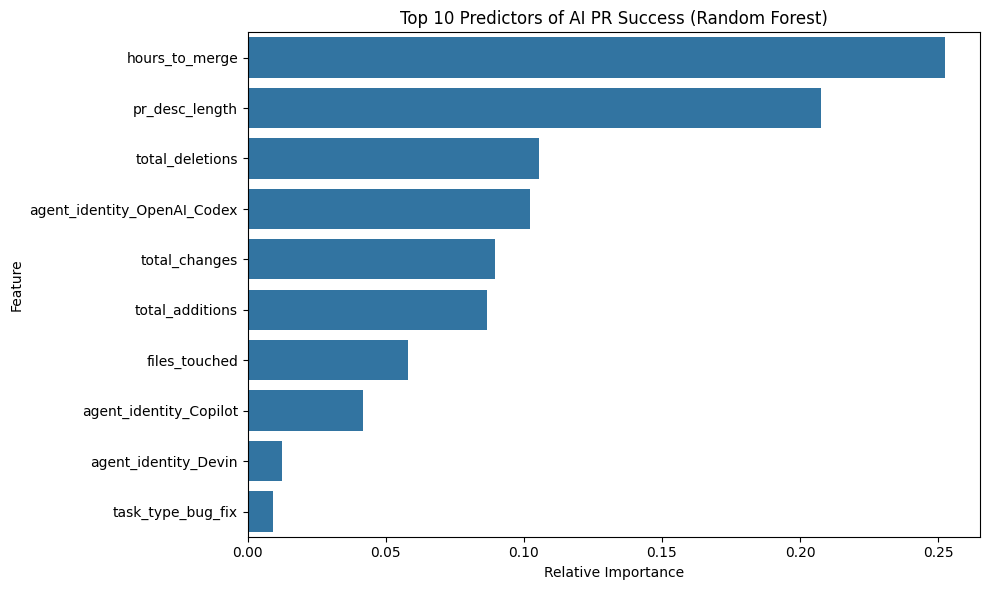

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. PREPARE THE DATA FOR MODELING
# Drop the 'id' column as it is not a predictive feature
X = final_ml_dataset.drop(columns=['id', 'target_heavy_review'])
y = final_ml_dataset['target_heavy_review']

# Split the data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. TRAIN THE RANDOM FOREST MODEL
# We use 100 decision trees to build a robust model, and balance the weights
# in case there are far more smooth merges than heavy reviews.
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# 3. EVALUATE THE MODEL
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1] # Probabilities for the ROC curve

print("Model Evaluation Report:")
print("-" * 50)
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print("-" * 50)

# 4. FEATURE IMPORTANCE ANALYSIS
# This tells us WHICH features drive PR success or failure
importances = rf_model.feature_importances_
feature_names = X.columns

# Create a DataFrame for easy plotting
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot the top predictors
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10))
plt.title('Top 10 Predictors of AI PR Success (Random Forest)')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


In [10]:
# You may need to run this command in a separate cell first if imblearn is not installed:
# !pip install imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report

print("--- METHOD 1: SMOTE (Synthetic Data Generation) ---")
# 1. Apply SMOTE to the training data ONLY
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# 2. Train a new Random Forest on the SMOTE data
rf_smote = RandomForestClassifier(n_estimators=100, random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)

# 3. Evaluate SMOTE Model
y_pred_smote = rf_smote.predict(X_test)
print(classification_report(y_test, y_pred_smote))


print("\n--- METHOD 2: THRESHOLD TUNING (Using our original model) ---")
# 1. Get the raw probabilities from our very first model (from Cell 5)
# rf_model is the original model we trained
y_prob_original = rf_model.predict_proba(X_test)[:, 1]

# 2. Lower the threshold from the default 0.50 down to 0.30
custom_threshold = 0.30

# If probability > 30%, predict 1 (Heavy Review). Otherwise, predict 0.
y_pred_custom_threshold = (y_prob_original >= custom_threshold).astype(int)

# 3. Evaluate Threshold Tuning
print(classification_report(y_test, y_pred_custom_threshold))


--- METHOD 1: SMOTE (Synthetic Data Generation) ---
              precision    recall  f1-score   support

           0       0.93      0.93      0.93      5780
           1       0.60      0.60      0.60       940

    accuracy                           0.89      6720
   macro avg       0.77      0.77      0.77      6720
weighted avg       0.89      0.89      0.89      6720


--- METHOD 2: THRESHOLD TUNING (Using our original model) ---
              precision    recall  f1-score   support

           0       0.95      0.92      0.93      5780
           1       0.57      0.69      0.62       940

    accuracy                           0.88      6720
   macro avg       0.76      0.80      0.78      6720
weighted avg       0.89      0.88      0.89      6720



In [11]:
# You may need to run this command if xgboost is not installed:
# !pip install xgboost

import xgboost as xgb
from sklearn.metrics import classification_report

# 1. Calculate the ratio of Smooth Merges to Heavy Reviews
# This tells XGBoost exactly how much to penalize missing a Heavy Review
# (Count of Class 0 / Count of Class 1)
pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])

print(f"Calculated scale_pos_weight: {pos_weight:.2f}")
print("Training XGBoost...")

# 2. Initialize the XGBoost Classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=200,          # More trees than Random Forest
    learning_rate=0.05,        # Learns slowly and carefully
    max_depth=5,               # Prevents overfitting
    scale_pos_weight=pos_weight, # THE MAGIC SAUCE: Automatically handles the 14% imbalance
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

# 3. Train the model
xgb_model.fit(X_train, y_train)

# 4. Evaluate
y_pred_xgb = xgb_model.predict(X_test)

print("\n--- METHOD 3: XGBoost with Built-in Imbalance Handling ---")
print(classification_report(y_test, y_pred_xgb))


Calculated scale_pos_weight: 6.40
Training XGBoost...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [23:58:21] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



--- METHOD 3: XGBoost with Built-in Imbalance Handling ---
              precision    recall  f1-score   support

           0       0.97      0.83      0.90      5780
           1       0.46      0.86      0.60       940

    accuracy                           0.84      6720
   macro avg       0.72      0.85      0.75      6720
weighted avg       0.90      0.84      0.86      6720



In [12]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
from sklearn.metrics import classification_report

# 1. Define the XGBoost model (keeping our 14% imbalance fix)
xgb_model = xgb.XGBClassifier(
    scale_pos_weight=pos_weight,
    random_state=42,
    eval_metric='logloss'
)

# 2. Define the Hyperparameters we want to test (NO PCA!)
param_distributions = {
    'n_estimators': [100, 200, 300, 400],     # Number of trees
    'max_depth': [3, 5, 7, 9],                # How deep the trees can go
    'learning_rate': [0.01, 0.05, 0.1, 0.2],  # How fast it learns
    'subsample': [0.7, 0.8, 0.9, 1.0],        # Row sampling to prevent overfitting
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]  # Column sampling to prevent overfitting
}

# 3. Setup Randomized Search
print("Starting Hyperparameter Tuning WITHOUT PCA...")
random_search_xgb = RandomizedSearchCV(
    xgb_model,
    param_distributions=param_distributions,
    n_iter=30,    # Test 30 different combinations
    cv=3,         # 3-Fold Cross Validation
    scoring='f1', # Optimize the balance of Precision and Recall
    verbose=1,
    random_state=42,
    n_jobs=-1     # Use all computer cores
)

# 4. Train the model
random_search_xgb.fit(X_train, y_train)

# 5. Evaluate the absolute best model it found
print("\n--- BEST SETTINGS FOUND ---")
for key, value in random_search_xgb.best_params_.items():
    print(f"{key}: {value}")

best_xgb = random_search_xgb.best_estimator_
y_pred_best = best_xgb.predict(X_test)

print("\n--- FINAL MODEL: Hyperparameter Tuned XGBoost (NO PCA) ---")
print(classification_report(y_test, y_pred_best))


Starting Hyperparameter Tuning WITHOUT PCA...
Fitting 3 folds for each of 30 candidates, totalling 90 fits

--- BEST SETTINGS FOUND ---
subsample: 0.7
n_estimators: 300
max_depth: 9
learning_rate: 0.01
colsample_bytree: 0.8

--- FINAL MODEL: Hyperparameter Tuned XGBoost (NO PCA) ---
              precision    recall  f1-score   support

           0       0.97      0.86      0.91      5780
           1       0.49      0.81      0.61       940

    accuracy                           0.86      6720
   macro avg       0.73      0.84      0.76      6720
weighted avg       0.90      0.86      0.87      6720



In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("--- TRAINING NEW MODEL: Logistic Regression ---")

# 1. Logistic Regression requires scaled data to perform well
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Initialize and train the model
# We use class_weight='balanced' to handle the 14% class imbalance automatically
log_reg_model = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
log_reg_model.fit(X_train_scaled, y_train)

# 3. Evaluate the model
y_pred_log_reg = log_reg_model.predict(X_test_scaled)

print("Model Evaluation Report:")
print("-" * 50)
print(classification_report(y_test, y_pred_log_reg))
print("-" * 50)

--- TRAINING NEW MODEL: Logistic Regression ---
Model Evaluation Report:
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.97      0.74      0.84      5780
           1       0.34      0.84      0.49       940

    accuracy                           0.75      6720
   macro avg       0.66      0.79      0.66      6720
weighted avg       0.88      0.75      0.79      6720

--------------------------------------------------


In [14]:
import pandas as pd
from IPython.display import display

# 1. Gather metrics for Random Forest (from your rf_model)
rf_acc = accuracy_score(y_test, y_pred)
rf_prec = precision_score(y_test, y_pred)
rf_rec = recall_score(y_test, y_pred)
rf_f1 = f1_score(y_test, y_pred)

# 2. Gather metrics for Logistic Regression (from your log_reg_model)
lr_acc = accuracy_score(y_test, y_pred_log_reg)
lr_prec = precision_score(y_test, y_pred_log_reg)
lr_rec = recall_score(y_test, y_pred_log_reg)
lr_f1 = f1_score(y_test, y_pred_log_reg)

# 3. Gather metrics for Tuned XGBoost (from your best_xgb model)
xgb_acc = accuracy_score(y_test, y_pred_best)
xgb_prec = precision_score(y_test, y_pred_best)
xgb_rec = recall_score(y_test, y_pred_best)
xgb_f1 = f1_score(y_test, y_pred_best)

# 4. Create the Comparison DataFrame
comparison_data = {
    'Classification Model': ['Random Forest ', 'Logistic Regression ', 'XGBoost '],
    'Overall Accuracy': [rf_acc, lr_acc, xgb_acc],
    'Precision (Class 1)': [rf_prec, lr_prec, xgb_prec],
    'Recall (Class 1)': [rf_rec, lr_rec, xgb_rec],
    'F1-Score (Class 1)': [rf_f1, lr_f1, xgb_f1]
}

comparison_df = pd.DataFrame(comparison_data)

# Format the numbers as percentages for a clean presentation table
for col in comparison_df.columns[1:]:
    comparison_df[col] = (comparison_df[col] * 100).round(1).astype(str) + '%'

print("--- FINAL MODEL METRICS COMPARISON ---")
display(comparison_df)

--- FINAL MODEL METRICS COMPARISON ---


,Classification Model,Overall Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1)
0,Random Forest (Baseline),89.5%,69.2%,45.1%,54.6%
1,Logistic Regression (Linear),75.3%,34.4%,84.5%,48.9%
2,XGBoost (Tuned Champion),85.6%,49.0%,80.7%,61.0%
